# Matplotlib : transformer un graphique brut en graphique professionnel

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Plotting/Matplotlib-Graphiques-Pro.ipynb)

📖 **Le shot complet** : [Matplotlib n'est pas limité. Tu l'utilises mal.](https://www.monshotdata.com/p/matplotlib-graphiques-pro)

---

Le graphique par défaut de Matplotlib est correct, mais il ressemble à un graphique par défaut : grille, cadre, étiquettes partout, aucune idée mise en avant. Quelques réglages le transforment en graphique qu'on peut montrer dans un rapport ou une présentation. Ici on part d'un diagramme en barres brut et on l'améliore étape par étape.

**À la fin de ce notebook, tu sauras :**

- trier les données et passer en barres horizontales pour que le classement se lise d'un coup d'œil ;
- mettre en valeur **une seule barre** et supprimer tout ce qui encombre (cadre, axe, grille) ;
- écrire un titre qui énonce le message, et poser titre, sous-titre, filet et note de bas de graphique avec les coordonnées de la figure.

### Avant de lancer

- **Installation** : rien : Pandas, NumPy et Matplotlib sont déjà là dans Colab et Jupyter.
- **Les données** : cinq catégories de dépenses avec une marge bénéficiaire **fictive**, écrites directement dans le notebook.
- **Les polices** : le graphique final utilise une police à empattements pour le titre (Times New Roman) et une police sans empattements pour la note (Arial). Si elles ne sont pas installées (c'est le cas sur Colab et sous Linux), une cellule choisit automatiquement une police équivalente : le rendu reste proche.

🧪 *Testé le 22 novembre 2026 : exécution complète de haut en bas (Python 3.13, Pandas 3.0, NumPy 2.5 et Matplotlib 3.11). Les sorties affichées viennent de cette exécution.*

## 1. Mise en place

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager

Les polices installées varient d'une machine à l'autre. Cette petite fonction prend la première police disponible dans une liste de préférences, pour que le notebook fonctionne partout sans avertissement :

In [2]:
def premiere_police(*candidates):
    """Renvoie la première police de la liste installée sur cette machine."""
    installees = {f.name for f in font_manager.fontManager.ttflist}
    return next((c for c in candidates if c in installees), "DejaVu Sans")

# Times New Roman sur Windows/Mac, Liberation Serif sur Linux et Colab, DejaVu Serif en dernier recours
POLICE_TITRE = premiere_police("Times New Roman", "Liberation Serif", "DejaVu Serif")
# Arial sur Windows/Mac, Liberation Sans sur Linux et Colab
POLICE_TEXTE = premiere_police("Arial", "Liberation Sans", "DejaVu Sans")

print("Titre :", POLICE_TITRE, "| Texte :", POLICE_TEXTE)

Titre : Liberation Serif | Texte : Liberation Sans


## 2. Les données

In [3]:
df = pd.DataFrame(
    [["Vêtements", 0.10],
     ["Décoration intérieure", 0.43],
     ["Électronique", 0.13],
     ["Papeterie", 0.20],
     ["Jouets", 0.14]],
    columns=["Spend_Category", "Profit_Margin"],
)
df

,Spend_Category,Profit_Margin
0,Vêtements,0.10
1,Décoration intérieure,0.43
2,Électronique,0.13
3,Papeterie,0.20
4,Jouets,0.14


## 3. Le graphique de départ

Un diagramme en barres verticales, avec le titre, les étiquettes d'axe et la grille par défaut. Il est exact, mais le lecteur doit chercher ce qu'il faut y voir.

In [4]:
def percent_formatter(x, pos):
    return f"{x*100:.0f}%"

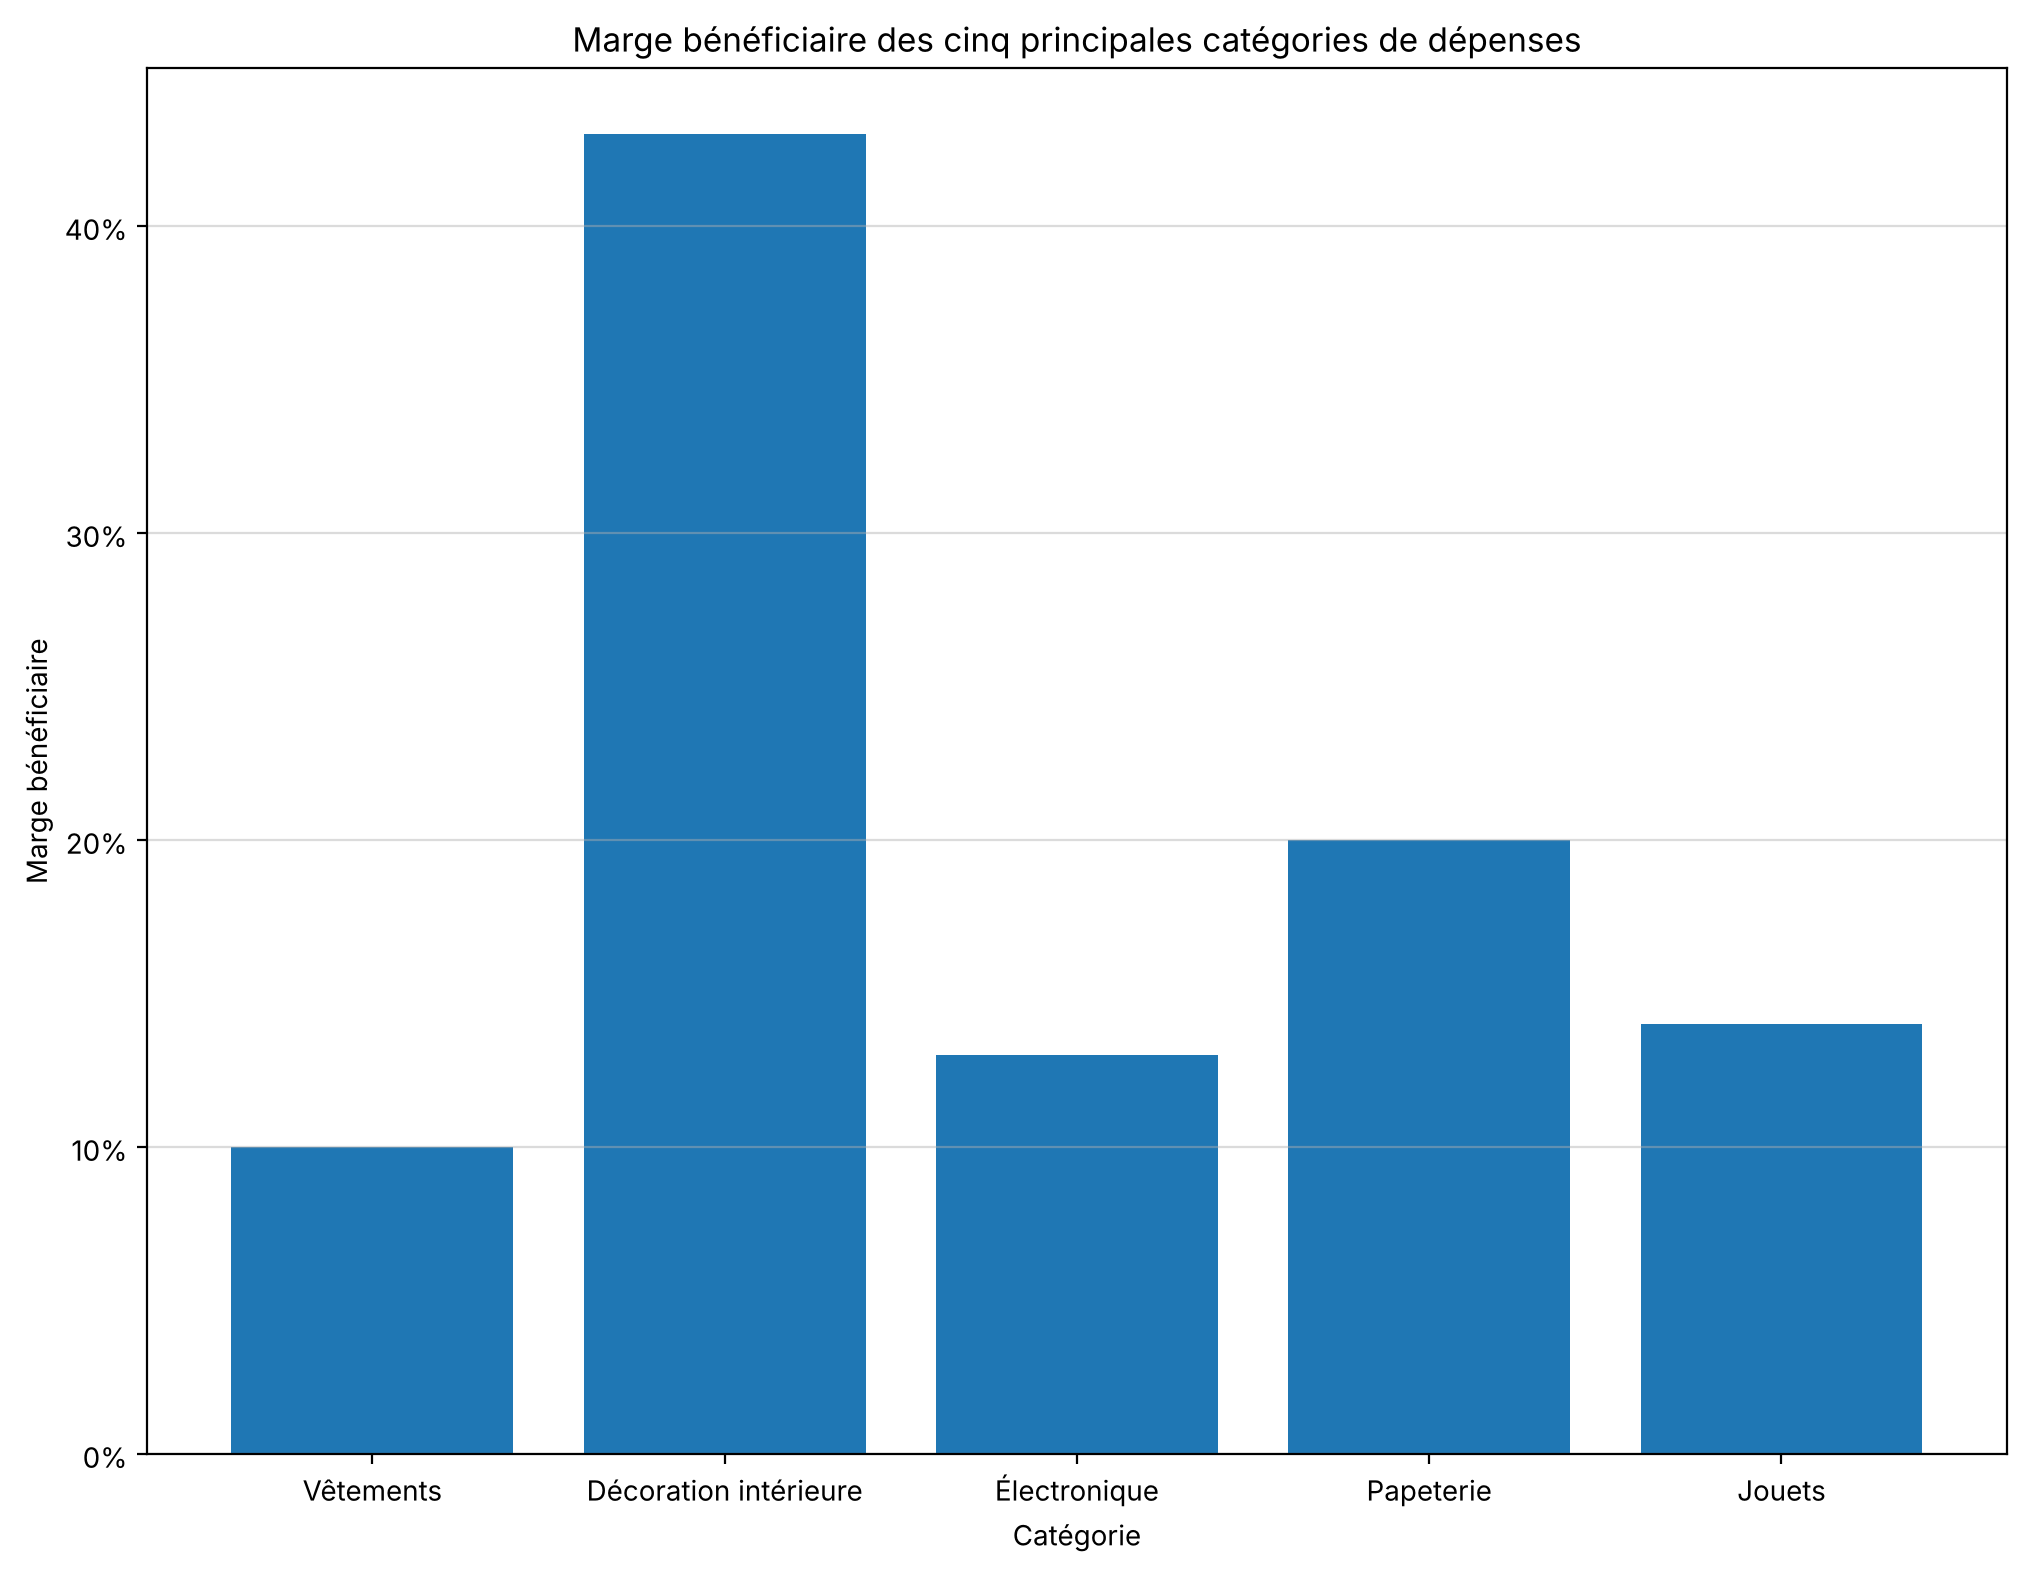

In [5]:
fig, ax = plt.subplots(figsize=(12, 9))

ax.bar(df["Spend_Category"], df["Profit_Margin"])

# Convertit les graduations de l'axe Y en pourcentage
ax.yaxis.set_major_formatter(mtick.FuncFormatter(percent_formatter))

ax.grid(axis="y", alpha=0.45)
ax.set_title("Marge bénéficiaire des cinq principales catégories de dépenses")
ax.set_ylabel("Marge bénéficiaire")
ax.set_xlabel("Catégorie")

plt.show()

## 4. Trier, passer en horizontal : le classement se lit tout seul

Deux changements simples :

- **trier** les barres par valeur, pour que l'œil suive un classement ;
- passer en **barres horizontales** (`barh`), qui laissent la place à des noms de catégories longs sans les pencher.

In [6]:
# Tri croissant : avec barh, la plus grande barre se retrouve en haut
df = df.sort_values("Profit_Margin", ascending=True, ignore_index=True)
df

,Spend_Category,Profit_Margin
0,Vêtements,0.10
1,Électronique,0.13
2,Jouets,0.14
3,Papeterie,0.20
4,Décoration intérieure,0.43


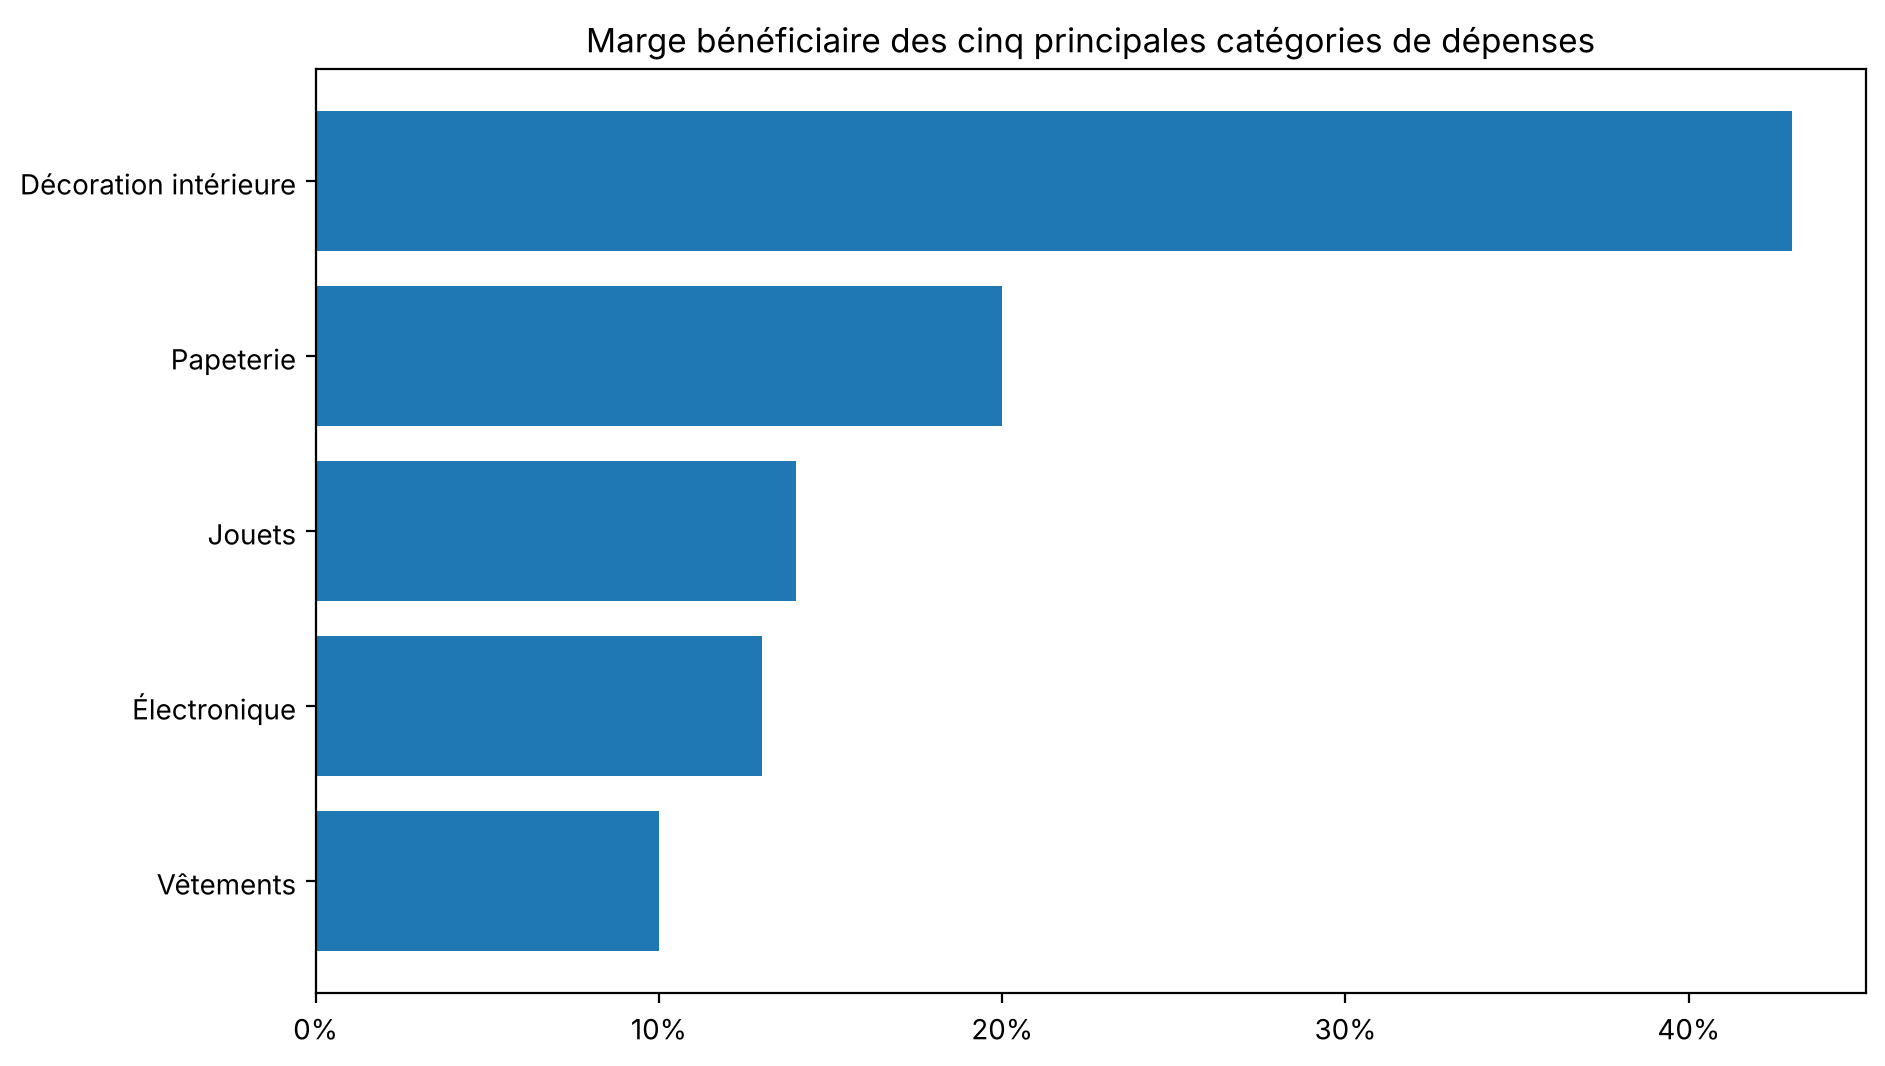

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(df["Spend_Category"], df["Profit_Margin"])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(percent_formatter))
ax.set_title("Marge bénéficiaire des cinq principales catégories de dépenses")

plt.show()

## 5. Le graphique final, étape par étape

Le graphique final regroupe sept améliorations. Elles sont dans **une seule cellule**, commentée ligne par ligne, parce qu'elles s'appliquent à la même figure :

| Étape | Ce qu'on fait | Pourquoi |
|---|---|---|
| Titre | un titre qui énonce le **message**, pas seulement le sujet | le lecteur comprend avant même de regarder les barres |
| Couleurs | une barre noire, les autres gris clair | l'attention va à la catégorie qui compte |
| Cadre | on supprime les 4 bordures | moins d'encre sans information |
| Axe X | on supprime l'axe et ses graduations | les valeurs sont écrites sur les barres |
| Étiquettes | `bar_label` écrit la valeur au bout de chaque barre | pas besoin de lire une échelle |
| Filet et rectangle | un trait et un petit carré en haut à gauche | un repère visuel qui structure l'en-tête |
| Note | la source et la période, en italique, en bas | le lecteur sait d'où viennent les chiffres |

Les éléments de texte, le filet et le rectangle sont placés avec `transform=fig.transFigure` : leurs coordonnées vont de 0 à 1 **sur la figure entière** (et non sur le graphique), ce qui permet de les poser librement autour des axes.

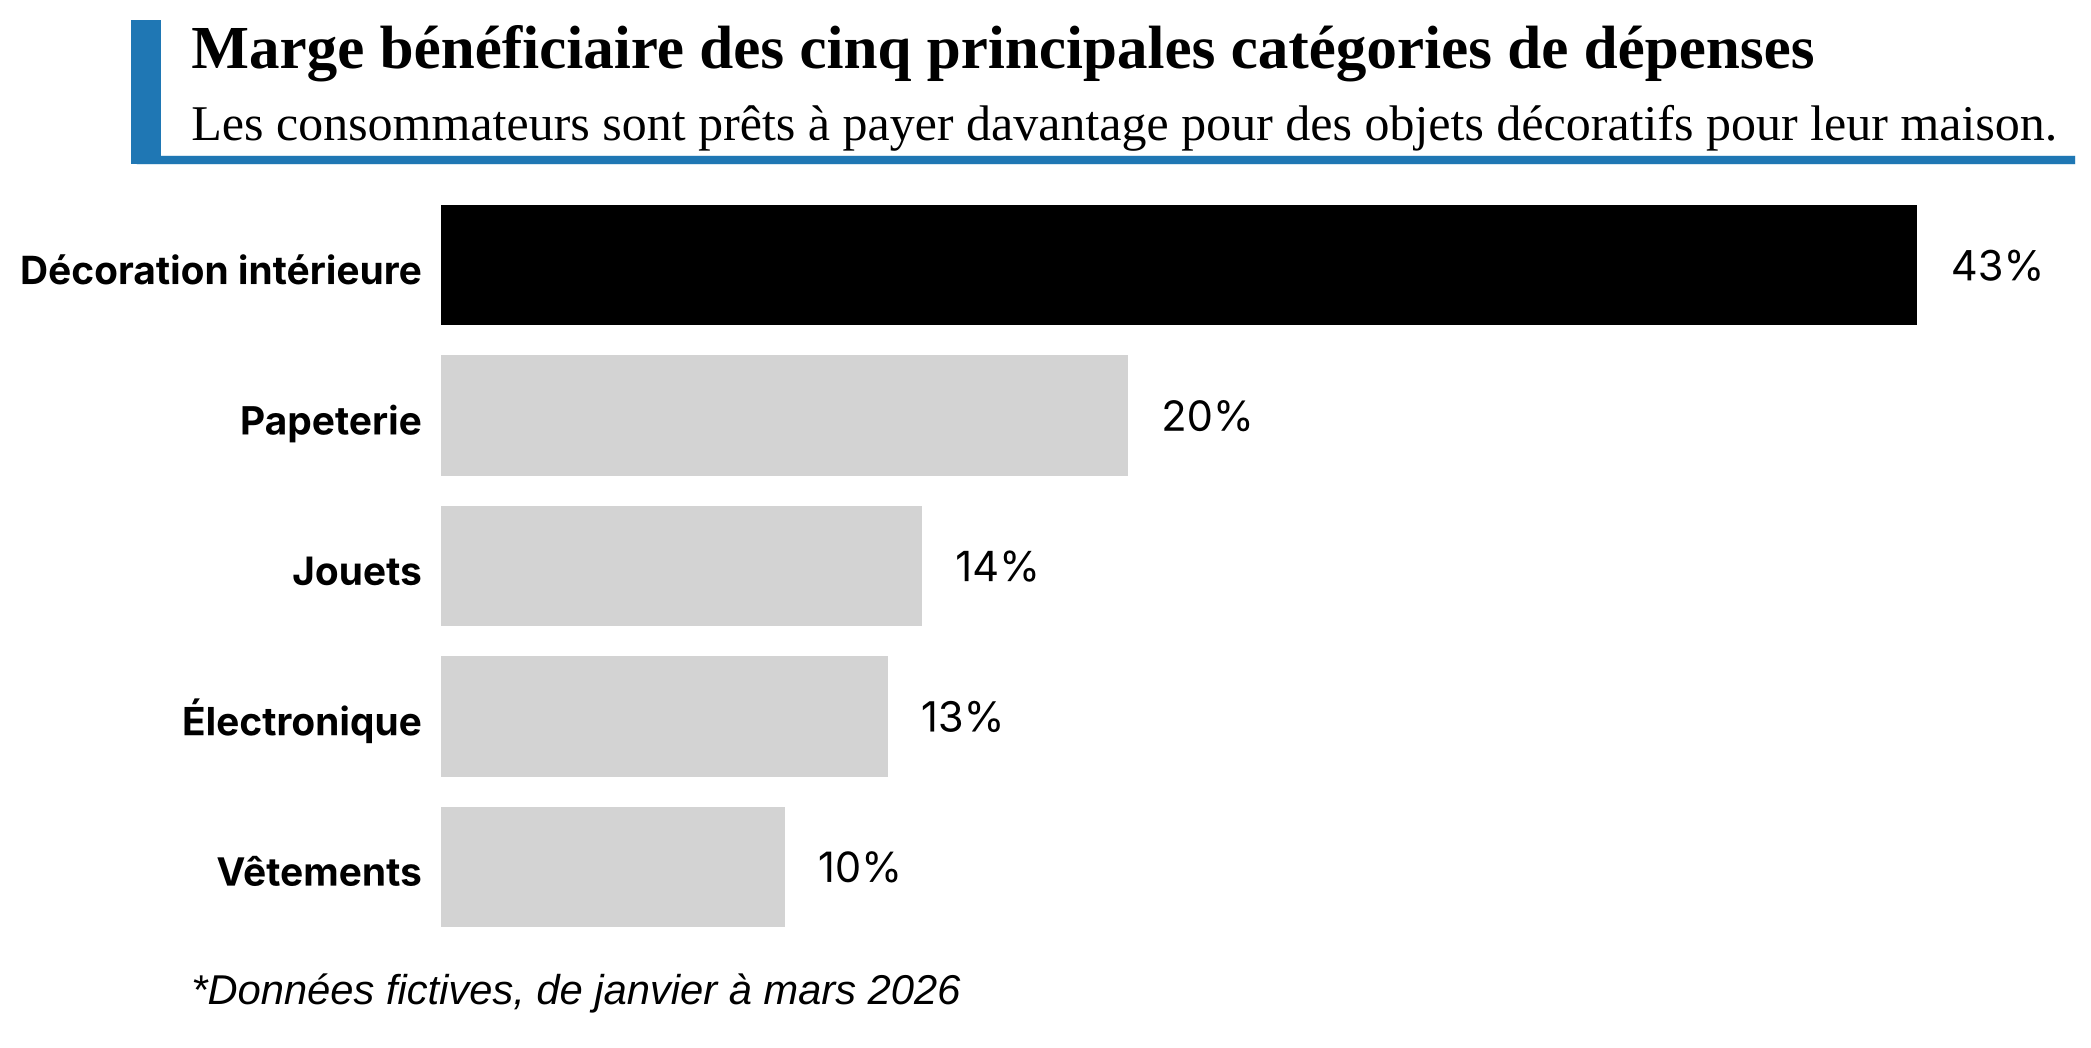

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

# --- Titre et sous-titre, placés avec les coordonnées de la figure (0 à 1) ---
titre = "Marge bénéficiaire des cinq principales catégories de dépenses"
fig.text(x=0, y=0.91, s=titre,
         fontname=POLICE_TITRE, fontweight="bold", fontsize=22,
         ha="left")

sous_titre = "Les consommateurs sont prêts à payer davantage pour des objets décoratifs pour leur maison."
fig.text(x=0, y=0.85, s=sous_titre,
         fontname=POLICE_TITRE, fontsize=18,
         ha="left")

# --- Barres : la dernière (la plus grande après le tri) en noir, les autres en gris clair ---
couleurs = ["lightgray"] * (len(df) - 1) + ["black"]
barres = ax.barh(df["Spend_Category"], df["Profit_Margin"],
                 color=couleurs, edgecolor="none")

ax.margins(y=0.14)   # un peu d'air au-dessus et en dessous des barres

# --- On supprime le cadre et l'axe X ---
for cote in ["top", "right", "bottom", "left"]:
    ax.spines[cote].set_visible(False)
ax.set_xticks([])   # plus de graduations : les valeurs sont écrites sur les barres

# --- Noms des catégories : plus gros, en gras, sans petit trait de graduation ---
ax.tick_params(axis="y", left=False)
ax.set_yticks(range(len(df)), df["Spend_Category"], fontsize=14, fontweight="bold")

# --- Valeur au bout de chaque barre ---
ax.bar_label(barres,
             labels=[f"{x:.0%}" for x in barres.datavalues],
             padding=12, fontsize=15)

# --- Filet horizontal sous le sous-titre ---
ax.plot([-0.025, 0.94], [0.8335, 0.8335],
        transform=fig.transFigure, clip_on=False,
        color="tab:blue", linewidth=3)

# --- Petit rectangle décoratif à gauche du titre ---
ax.add_patch(plt.Rectangle((-0.03, 0.95), 0.015, -0.12,
                           facecolor="tab:blue", transform=fig.transFigure,
                           clip_on=False, linewidth=0))

# --- Note de bas de graphique ---
fig.text(x=0, y=0.13, s="*Données fictives, de janvier à mars 2026",
         fontname=POLICE_TEXTE, fontstyle="italic", fontsize=15,
         ha="left")

plt.show()

Les barres grises donnent le contexte, la barre noire donne le message, et le titre l'écrit en toutes lettres. Aucun élément n'est là pour décorer.

## 6. Réutiliser le style : une fonction

Une fois le résultat obtenu, on évite de recopier 40 lignes : on range le tout dans une fonction qui prend les données et les textes. La barre mise en valeur est celle de la **plus grande valeur**, quelles que soient les données.

In [9]:
def graphique_pro(donnees, colonne_nom, colonne_valeur, titre, sous_titre, note):
    donnees = donnees.sort_values(colonne_valeur, ascending=True, ignore_index=True)

    fig, ax = plt.subplots(figsize=(10, 6))

    fig.text(0, 0.91, titre, fontname=POLICE_TITRE, fontweight="bold", fontsize=22, ha="left")
    fig.text(0, 0.85, sous_titre, fontname=POLICE_TITRE, fontsize=18, ha="left")

    couleurs = ["lightgray"] * (len(donnees) - 1) + ["black"]
    barres = ax.barh(donnees[colonne_nom], donnees[colonne_valeur], color=couleurs, edgecolor="none")
    ax.margins(y=0.14)

    for cote in ["top", "right", "bottom", "left"]:
        ax.spines[cote].set_visible(False)
    ax.set_xticks([])
    ax.tick_params(axis="y", left=False)
    ax.set_yticks(range(len(donnees)), donnees[colonne_nom], fontsize=14, fontweight="bold")

    ax.bar_label(barres, labels=[f"{x:.0%}" for x in barres.datavalues], padding=12, fontsize=15)

    ax.plot([-0.025, 0.94], [0.8335, 0.8335], transform=fig.transFigure, clip_on=False,
            color="tab:blue", linewidth=3)
    ax.add_patch(plt.Rectangle((-0.03, 0.95), 0.015, -0.12, facecolor="tab:blue",
                               transform=fig.transFigure, clip_on=False, linewidth=0))
    fig.text(0, 0.13, note, fontname=POLICE_TEXTE, fontstyle="italic", fontsize=15, ha="left")

    plt.show()

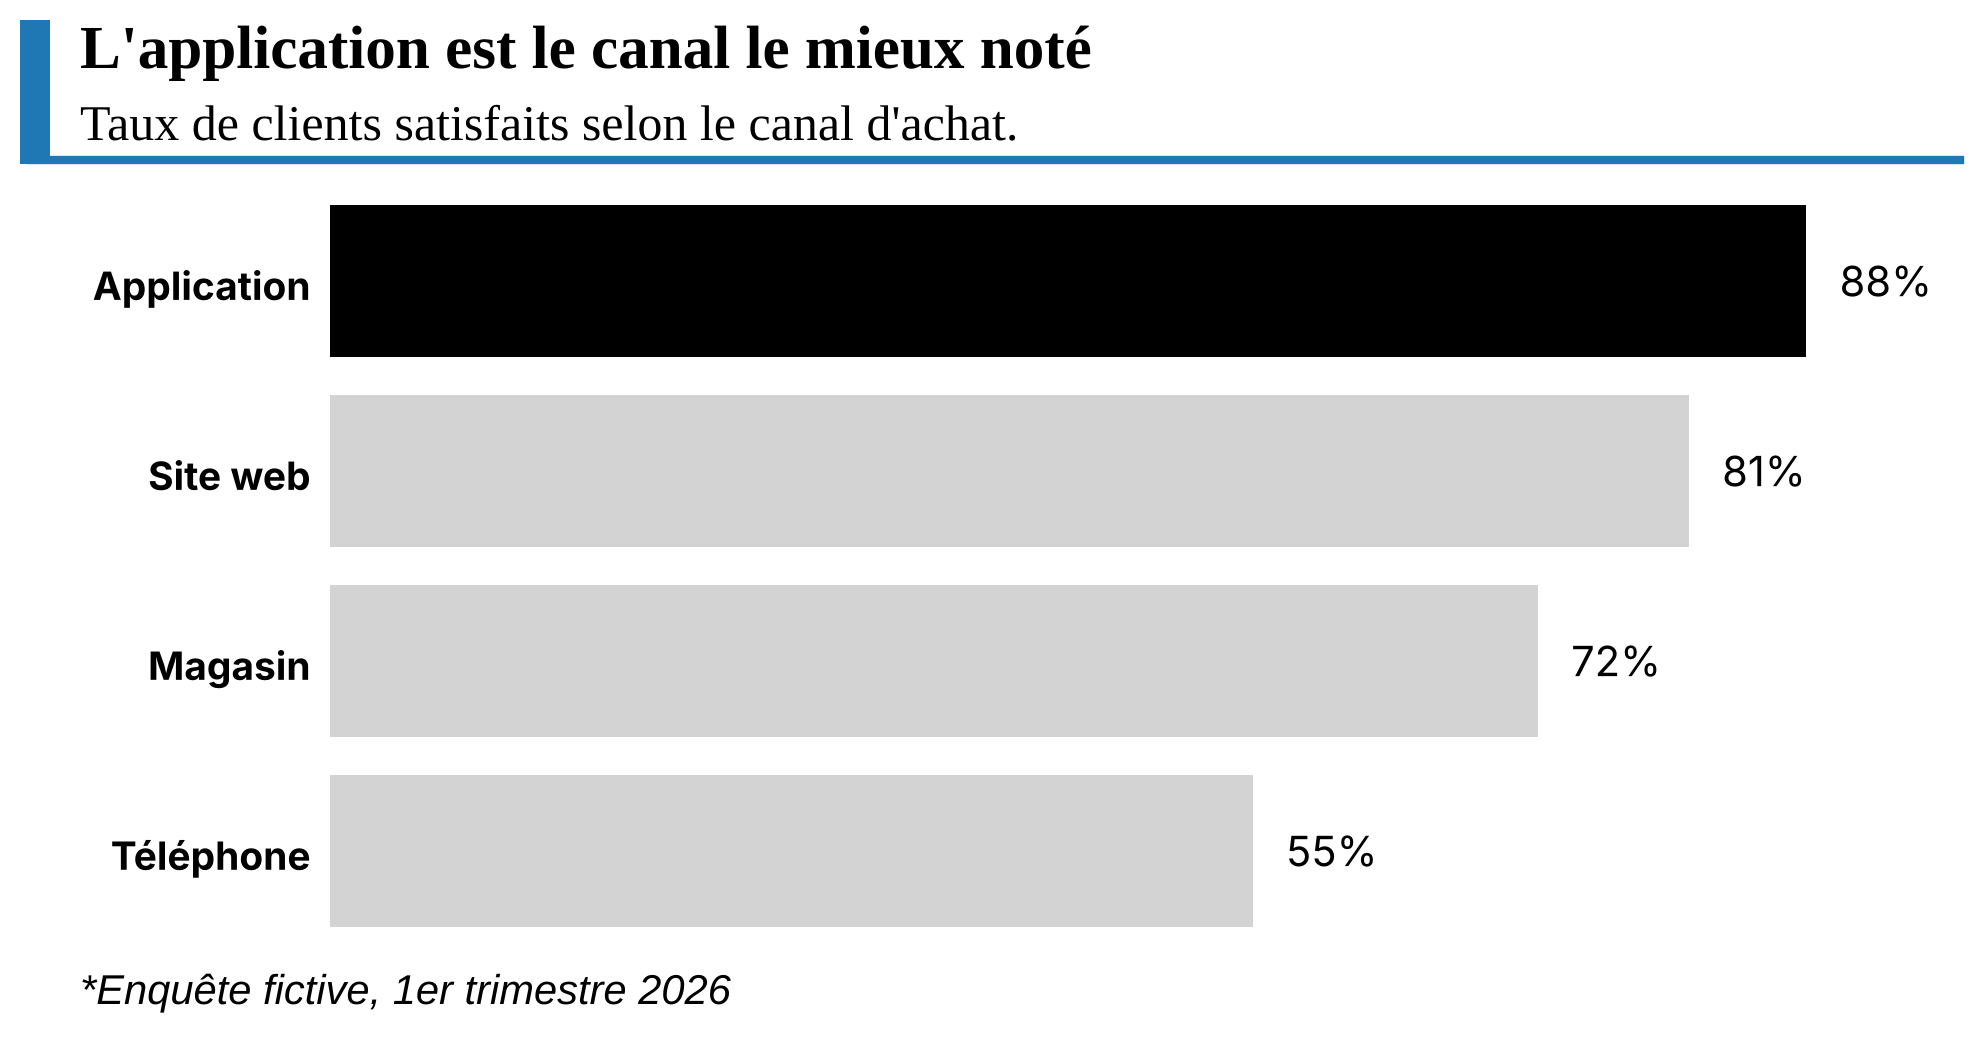

In [10]:
# Mêmes réglages, autres données (fictives)
satisfaction = pd.DataFrame({
    "Canal": ["Magasin", "Site web", "Application", "Téléphone"],
    "Taux": [0.72, 0.81, 0.88, 0.55],
})

graphique_pro(
    satisfaction, "Canal", "Taux",
    titre="L'application est le canal le mieux noté",
    sous_titre="Taux de clients satisfaits selon le canal d'achat.",
    note="*Enquête fictive, 1er trimestre 2026",
)

## 7. Ce qu'il faut retenir

- Un graphique professionnel retire plus qu'il n'ajoute : cadre, axe, grille et étiquettes superflues.
- Trie les barres et utilise `barh` quand les noms de catégories sont longs.
- Une seule couleur vive (ou un noir) sur fond gris clair guide l'attention vers le message.
- Écris un titre qui énonce le message, avec un sous-titre qui le précise.
- `transform=fig.transFigure` place un texte, un trait ou un rectangle avec des coordonnées de 0 à 1 sur toute la figure.
- `bar_label` écrit les valeurs sur les barres, et `premiere_police` rend le notebook portable d'une machine à l'autre.

---

## Pour aller plus loin

- [Rends tes tracés Matplotlib plus professionnels](https://www.monshotdata.com/p/rends-tes-traces-matplotlib-plus-professionnels) — d'autres réglages pour des tracés plus lisibles
- [Style Matplotlib : rendre ses tracés plus attractifs](https://www.monshotdata.com/p/style-des-traces-matplotlib) — changer le style de tous tes graphiques en une ligne
- [Rends tes graphiques plus parlants !](https://www.monshotdata.com/p/graphiques-annotes) — annoter un graphique pour guider le regard
- [Tous les notebooks des shots](https://github.com/moncoachdata/MonShotData) — le code Python de la newsletter, rangé par thème